# Adversarial Search: Solving Tic-Tac-Toe with Minimax Search and Alpha-Beta Pruning

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. __Optimal Decisions:__ Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* __minimax search,__
* __minimax search with alpha-beta pruning,__ and
* __move ordering__. 

The search time (number if nodes explored) could be further improved by 
* __heuristic alpha-beta tree search__ (cut off search and use heuristic evaluation function to approximate utility), 
* __forward pruning__ (prune moves that appear poor), and
* __table lookups__ (for openings and end game).

The algorithms search the game tree and we could return a conditional plan (or partial plan if cut offs are used), but the implementation here only identifies and returns the optimal next move.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# --- bổ sung: thư viện, seed và bản sao hàm actions gốc (chưa sắp xếp nước đi) ---
import time
import numpy as np
np.random.seed(2024)
actions_plain = actions

# Recursive DFS algorithm for Minimax Search

See AIMA page 150. 

Note that the minimax search algorithm is very similar to AND-OR search where max does OR and min is represented by AND nodes.

In [3]:
import math

# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def minimax_search(board, player = 'x'):
    """start the search."""
    global DEBUG, COUNT
    COUNT = 0
    
    value, move = max_value(board, player)
    
    if DEBUG >= 1: print(f"Number of nodes searched: {COUNT}") 
 
    return { "move": move, "value": value}

def max_value(state, player):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state if it is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print("max in: " + str(state) + str([v]) ) 
    if v is not None: return v, None
        
    v, move = -math.inf, None

    # check all possible actions in the state, return move with the largest value
    for a in actions(state):
        v2, a2 = min_value(result(state, player, a), player)
        if v2 > v:
            v, move = v2, a
    
    if DEBUG >= 2: print("max out: " + str(state) + str([v, move]) ) 
    return v, move

def min_value(state, player):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state if it is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print("min in: " + str(state) + str([v]) ) 
    if v is not None: return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value(result(state, other(player), a), player)
        if v2 < v:
            v, move = v2, a
    
    if DEBUG >= 2: print("min out: " + str(state) + str([v, move]) ) 
    return v, move

## Some Tests

### x is about to win (choose 8)

Board:


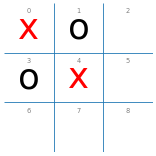


Number of nodes searched: 190


{'move': 2, 'value': 1}

CPU times: total: 0 ns
Wall time: 5.96 ms


In [4]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

**Note:** DFS does not pick the the shortest path to a win! Discounting the utility can help.

### x can draw if it chooses 7

Board:


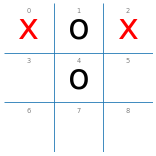


Number of nodes searched: 206


{'move': 7, 'value': 0}

CPU times: total: 0 ns
Wall time: 8.94 ms


In [5]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

### A bad situation


Board:


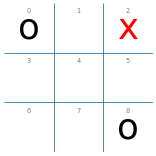


Number of nodes searched: 941


{'move': 1, 'value': -1}

CPU times: total: 15.6 ms
Wall time: 26.7 ms


In [6]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

### Empty board

Board:


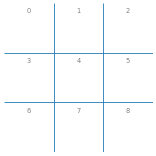


Number of nodes searched: 549946


{'move': 0, 'value': 0}

CPU times: total: 5.55 s
Wall time: 16.5 s


In [7]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(minimax_search(board))

__Note:__ Starting with an empty board searched the complete game tree and takes a while. The number of nodes above is the actual size of the complete game tree. A table with know 'openings' (e.g., place x in a corner, o chooses the center, etc.) would be helpful to speed things up.

# Recursive DFS algorithm for Minimax Search with Alpha-Beta Pruning

See AIMA page 154. 

Adds alpha-beta pruning to minimax search. Alpha and beta are used to maintain bounds on the minimax value of a node in the form `[alpha, beta]`. alpha means that the value is at least that high and beta means that the actual value is at most that high. Subtrees below a node that are worse than the currently known bound do not need to be further explored and can be pruned. Max uses alpha and Min uses beta for pruning.

The implementation is for player 'x' returns a the optimal next move.

In [8]:
# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def alpha_beta_search(board, player = 'x'):
    """start the search."""
    global DEBUG, COUNT
    COUNT = 0
    
    value, move = max_value_ab(board, player, -math.inf, +math.inf)
    
    if DEBUG >= 1: print(f"Number of nodes searched: {COUNT}") 
    
    return { "move": move, "value": value }

def max_value_ab(state, player, alpha, beta):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
       
    # return utility of state is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print(f"max: {state} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: 
        if DEBUG >= 2: print(f"     found terminal state. backtracking.")
        return v, None
        
    v, move = -math.inf, None

    # check all possible actions in the state, update alpha and return move with the largest value
    for a in actions(state):
        v2, a2 = min_value_ab(result(state, player, a), player, alpha, beta)
        if DEBUG >= 2: print(f"max: {state} (backtracked) [alpha,beta]=[{alpha},{beta}] v={v2}")
        
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta:
            if DEBUG >= 2: print(f"     v>=beta ({v}>={beta}): pruning remaining subtree (actions). backtracking.")
            return v, move
    
    return v, move

def min_value_ab(state, player, alpha, beta):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print(f"min: {state} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: 
        if DEBUG >= 2: print(f"     found terminal state. backtacking.")
        return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, update beta and return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value_ab(result(state, other(player), a), player, alpha, beta)
        if DEBUG >= 2: print(f"min: {state} (backtracked) [alpha,beta]=[{alpha},{beta}] v={v2}")
        
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: 
            if DEBUG >= 2: print(f"     v<=alpha ({v}<={alpha}): pruning remaining subtree (actions). backtracking.")
            return v, move
    
    return v, move

## Some Tests

### x is about to win (play 8)

Board:


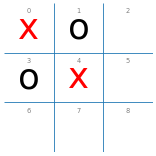


max: ['x', 'o', ' ', 'o', 'x', ' ', ' ', ' ', ' '] [alpha,beta]=[-inf,inf] v=None
min: ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', ' '] [alpha,beta]=[-inf,inf] v=None
max: ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '] [alpha,beta]=[-inf,inf] v=None
min: ['x', 'o', 'x', 'o', 'x', 'o', 'x', ' ', ' '] [alpha,beta]=[-inf,inf] v=1
     found terminal state. backtacking.
max: ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '] (backtracked) [alpha,beta]=[-inf,inf] v=1
min: ['x', 'o', 'x', 'o', 'x', 'o', ' ', 'x', ' '] [alpha,beta]=[1,inf] v=None
max: ['x', 'o', 'x', 'o', 'x', 'o', 'o', 'x', ' '] [alpha,beta]=[1,inf] v=None
min: ['x', 'o', 'x', 'o', 'x', 'o', 'o', 'x', 'x'] [alpha,beta]=[1,inf] v=1
     found terminal state. backtacking.
max: ['x', 'o', 'x', 'o', 'x', 'o', 'o', 'x', ' '] (backtracked) [alpha,beta]=[1,inf] v=1
min: ['x', 'o', 'x', 'o', 'x', 'o', ' ', 'x', ' '] (backtracked) [alpha,beta]=[1,inf] v=1
     v<=alpha (1<=1): pruning remaining subtree (actions). backtracking.
max: ['x', 'o'

{'move': 2, 'value': 1}

CPU times: total: 0 ns
Wall time: 4.76 ms


In [9]:
DEBUG = 2 # show more debugging info

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

The code does not pick the the shortest path to a win! Discounting could help.

### x can draw if it chooses 7

Board:


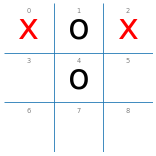


Number of nodes searched: 101


{'move': 7, 'value': 0}

CPU times: total: 0 ns
Wall time: 6.68 ms


In [10]:
DEBUG = 1

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

### o is about to win no matter what x does


Board:


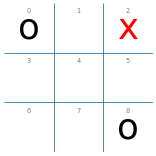


Number of nodes searched: 238


{'move': 1, 'value': -1}

CPU times: total: 0 ns
Wall time: 9.51 ms


In [11]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

### Empty board: Only a draw an be guaranteed

Board:


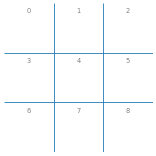


Number of nodes searched: 18297


{'move': 0, 'value': 0}

CPU times: total: 219 ms
Wall time: 547 ms


In [12]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board))

**Note:** Alpha-Beta search expands fewer nodes and is **much faster** than minimax search. 

## Move ordering

Smart move reordering can make alpha-beta pruning more effective. I think the center `[4]` and corners `[0, 2, 6, 8]` are good. I implement move reordering in the `actions()`.

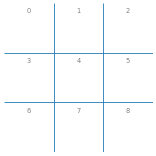

[4, 8, 6, 2, 0, 7, 5, 3, 1]

In [13]:
import numpy as np

def actions(board):
    """return possible actions as a vector ot indices"""
    actions = np.where(np.array(board) == ' ')[0].tolist()

    priority = [1,0,1,
                0,2,0,
                1,0,1]
    priority = [priority[i] for i in actions]
    
    actions =[a for _,a in sorted(zip(priority,actions), reverse=True)]
    
    return actions

board = empty_board()   
show_board(board)
actions(board)

### Empty board: Only a draw an be guaranteed

Board:


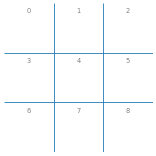


Number of nodes searched: 7275


{'move': 4, 'value': 0}

CPU times: total: 172 ms
Wall time: 299 ms


In [14]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board))

__Note:__ Compare to the number of nodes searched without move reordering (right above).

## Experiments


### Minimax with Alpha-Beta Pruning vs. Random

In [15]:
DEBUG = 0

def alpha_beta_player(board, player = 'x'):
    return alpha_beta_search(board, player)["move"]

print("alpha-beta vs. random:")
%time display(play(alpha_beta_player, random_player))

print()
print("random vs. alpha-beta")
%time display(play(random_player, alpha_beta_player))

alpha-beta vs. random:


{'x': 98, 'o': 0, 'd': 2}

CPU times: total: 17 s
Wall time: 34.2 s

random vs. alpha-beta


{'x': 0, 'o': 81, 'd': 19}

CPU times: total: 6.97 s
Wall time: 8.49 s


**Note on runtime:** Compared to AND-OR Search, Minimax search is slower, because AND-OR Search terminates once it finds the first subtree that has only goal nodes, buy Minimax search traverses the whole tree (minus what is pruned if alpha-beta pruning is used). 

Also, I was lazy and recreate the search tree every time the agent is asked for a move. The agent could create the tree with the Minimax values once and then use it to decide on actions. A problem could be that the tree may be too large to store. 

---
# So sánh Minimax và Alpha-Beta trên cùng tập trạng thái kiểm thử

> Từ đây là phần **bổ sung** cho Bài 3. Các hàm `minimax_search`, `alpha_beta_search` ở trên được giữ nguyên.

##  Sáu trạng thái kiểm thử (X đi tiếp)

Bốn trạng thái có sẵn trong notebook + hai trạng thái giữa ván (T5, T6). Cả hai thuật toán dùng cùng thứ tự nước đi gốc (`actions_plain`: ô trống theo chỉ số tăng dần) để so sánh công bằng.

In [16]:
def board_from(x=(), o=()):
    b = empty_board()
    for i in x: b[i] = 'x'
    for i in o: b[i] = 'o'
    return b

TESTS = {
    "T1 X sắp thắng":        board_from(x=(0, 4), o=(1, 3)),
    "T2 X cần hòa":          board_from(x=(0, 2), o=(1, 4)),
    "T3 bất lợi (O sắp thắng)": board_from(x=(2,), o=(0, 8)),
    "T4 bàn cờ rỗng":        empty_board(),
    "T5 X giữa, O góc":      board_from(x=(4,), o=(0,)),
    "T6 X góc, O giữa":      board_from(x=(0,), o=(4,)),
}

def bench(search_fn, board, player='x'):
    """Chạy một thuật toán, trả về (nước đi, giá trị, số nút, thời gian ms)."""
    global DEBUG
    old = DEBUG; DEBUG = 0
    t0 = time.perf_counter()
    r = search_fn(board, player)
    dt = (time.perf_counter() - t0) * 1000
    DEBUG = old
    return r["move"], r["value"], COUNT, dt

actions = actions_plain          # dùng thứ tự nước đi gốc
rows = []
for name, b in TESTS.items():
    mm = bench(minimax_search, b)
    ab = bench(alpha_beta_search, b)
    rows.append((name, mm, ab))

print(f"{'Trạng thái':<26}| {'Minimax: nước/giá trị/số nút/ms':<40}| {'Alpha-Beta: nước/giá trị/số nút/ms':<40}| {'Cùng QĐ':>7} | {'Giảm nút':>9}")
print("-" * 135)
for name, mm, ab in rows:
    same = (mm[0] == ab[0]) and (mm[1] == ab[1])
    print(f"{name:<26}| {str(mm[0]):>3} {mm[1]:>3} {mm[2]:>9} {mm[3]:>10.1f}      | {str(ab[0]):>3} {ab[1]:>3} {ab[2]:>9} {ab[3]:>10.1f}           | {str(same):>7} | {100*(1-ab[2]/mm[2]):>8.1f}%")

Trạng thái                | Minimax: nước/giá trị/số nút/ms         | Alpha-Beta: nước/giá trị/số nút/ms      | Cùng QĐ |  Giảm nút
---------------------------------------------------------------------------------------------------------------------------------------
T1 X sắp thắng            |   2   1       190        7.2      |   2   1        61        2.4           |    True |     67.9%
T2 X cần hòa              |   7   0       206       12.0      |   7   0       101        7.1           |    True |     51.0%
T3 bất lợi (O sắp thắng)  |   1  -1       941       47.7      |   1  -1       238       18.0           |    True |     74.7%
T4 bàn cờ rỗng            |   0   0    549946    29147.4      |   0   0     18297      595.1           |    True |     96.7%
T5 X giữa, O góc          |   1   0      6812      185.9      |   1   0       703       21.5           |    True |     89.7%
T6 X góc, O giữa          |   1   0      7332      195.9      |   1   0       844       25.4           |   

## Kiểm tra cắt tỉa không đổi quyết định tối ưu (trên 829 trạng thái)

Sáu trạng thái là chưa đủ để kết luận. Ta liệt kê **tất cả trạng thái phân biệt** có X đi tiếp sau 0, 2 và 4 nước đi đầu tiên (1 + 72 + 756 = 829 trạng thái, đều chưa kết thúc) và so sánh **nước đi** lẫn **giá trị Minimax** của hai thuật toán trên từng trạng thái.

In [17]:
def states_x_to_move(max_ply=4):
    level = {tuple(empty_board())}
    out = set(level)
    player = 'x'
    for ply in range(1, max_ply + 1):
        nxt = set()
        for s in level:
            for a in actions_plain(list(s)):
                nxt.add(tuple(result(list(s), player, a)))
        level = nxt
        player = other(player)
        if ply % 2 == 0:
            out |= level
    return sorted(out)

ALL = states_x_to_move(4)
actions = actions_plain
diff_move = diff_value = 0
tot_mm = tot_ab = 0
t_mm = t_ab = 0.0
for s in ALL:
    b = list(s)
    m1, v1, n1, t1 = bench(minimax_search, b)
    m2, v2, n2, t2 = bench(alpha_beta_search, b)
    diff_move += (m1 != m2); diff_value += (v1 != v2)
    tot_mm += n1; tot_ab += n2; t_mm += t1; t_ab += t2

print(f"Số trạng thái kiểm tra               : {len(ALL)}")
print(f"Số trạng thái khác NƯỚC ĐI            : {diff_move}")
print(f"Số trạng thái khác GIÁ TRỊ MINIMAX    : {diff_value}")
print(f"Tổng số nút  Minimax / Alpha-Beta     : {tot_mm:,} / {tot_ab:,}  (giảm {100*(1-tot_ab/tot_mm):.1f}%)")
print(f"Tổng thời gian Minimax / Alpha-Beta   : {t_mm/1000:.2f} s / {t_ab/1000:.2f} s")
assert diff_move == 0 and diff_value == 0

Số trạng thái kiểm tra               : 829
Số trạng thái khác NƯỚC ĐI            : 0
Số trạng thái khác GIÁ TRỊ MINIMAX    : 0
Tổng số nút  Minimax / Alpha-Beta     : 1,237,222 / 132,717  (giảm 89.3%)
Tổng thời gian Minimax / Alpha-Beta   : 42.27 s / 4.88 s


##  Move ordering – ảnh hưởng của thứ tự nước đi lên số nút của Alpha-Beta

Ba thứ tự được so sánh (Minimax thuần không bị ảnh hưởng vì luôn duyệt toàn bộ cây):

* **Gốc** – ô trống theo chỉ số tăng dần (0, 1, 2, …).
* **Tốt** – ưu tiên tâm (ô 4), rồi góc (0, 2, 6, 8), rồi cạnh (đúng như phần *Move ordering* của notebook).
* **Xấu** – đảo ngược: cạnh trước, góc sau, tâm cuối cùng.

In [18]:
def make_actions(priority):
    """Tạo hàm actions sắp xếp ô trống giảm dần theo (độ ưu tiên, chỉ số)."""
    def acts(board):
        free = [i for i in range(9) if board[i] == ' ']
        return sorted(free, key=lambda i: (priority[i], i), reverse=True)
    return acts

PRIORITY = [1, 0, 1,
            0, 2, 0,
            1, 0, 1]
ORDERINGS = {
    "Gốc (0..8)":            actions_plain,
    "Tốt (tâm>góc>cạnh)":    make_actions(PRIORITY),
    "Xấu (cạnh>góc>tâm)":    make_actions([2 - p for p in PRIORITY]),
}

subset = {k: TESTS[k] for k in ["T1 X sắp thắng", "T2 X cần hòa", "T3 bất lợi (O sắp thắng)", "T4 bàn cờ rỗng"]}
print(f"{'Thứ tự nước đi':<24}" + "".join(f"{k[:2]:>10}" for k in subset) + f"{'TB 829 TT':>12}{'T4 (ms)':>10}")
print("-" * 90)
ORD_RESULTS = {}
for oname, fn in ORDERINGS.items():
    actions = fn                       # alpha_beta_search dùng biến toàn cục `actions`
    nodes = []
    t_empty = 0
    for k, b in subset.items():
        m, v, n, t = bench(alpha_beta_search, b)
        nodes.append(n)
        if k.startswith("T4"): t_empty = t
    avg = sum(bench(alpha_beta_search, list(s))[2] for s in ALL) / len(ALL)
    ORD_RESULTS[oname] = (nodes, avg, t_empty)
    print(f"{oname:<24}" + "".join(f"{n:>10,}" for n in nodes) + f"{avg:>12.1f}{t_empty:>10.1f}")
actions = actions_plain               # khôi phục

# Kiểm tra: mọi thứ tự đều cho cùng giá trị Minimax trên bàn rỗng
vals = set()
for fn in ORDERINGS.values():
    actions = fn; vals.add(bench(alpha_beta_search, empty_board())[1])
actions = actions_plain
print("\nGiá trị Minimax của bàn rỗng với các thứ tự khác nhau:", vals)

Thứ tự nước đi                  T1        T2        T3        T4   TB 829 TT   T4 (ms)
------------------------------------------------------------------------------------------
Gốc (0..8)                      61       101       238    18,297       160.1     920.5
Tốt (tâm>góc>cạnh)              42       106        36     7,275       111.9     189.3
Xấu (cạnh>góc>tâm)              76        38       433    42,094       252.0    1153.2

Giá trị Minimax của bàn rỗng với các thứ tự khác nhau: {0}


### Nhận xét Bài 3

**1) So sánh Minimax và Alpha-Beta (mục 3.1).** Trên cả 6 trạng thái, hai thuật toán cho **cùng nước đi và cùng giá trị Minimax**; số nút của Alpha-Beta giảm từ 51% (T2) đến 96,7% (bàn rỗng: 549.946 → 18.297 nút, 1,04 s → 0,04 s). Ví dụ T1: cả hai chọn ô 2 với giá trị +1 (xem lại câu hỏi \"vì sao không chọn ô 8\": DFS trả về nước đầu tiên đạt giá trị lớn nhất, không ưu tiên nước thắng ngắn nhất).

**2) Cắt tỉa không đổi quyết định tối ưu (mục 3.2).** Trên **829** trạng thái phân biệt, có **0** trạng thái khác nước đi và **0** trạng thái khác giá trị Minimax (câu lệnh `assert` đã qua), trong khi tổng số nút giảm 89,3% (1.237.222 → 132.717). Lý do: nhánh bị cắt (`v >= beta` ở nút Max, `v <= alpha` ở nút Min) luôn là nhánh mà đối thủ *sẽ không bao giờ cho phép xảy ra* hoặc không thể cải thiện giá trị hiện có, nên không thể làm thay đổi giá trị gốc. Ở nút gốc cả hai thuật toán đều chọn nước **đầu tiên đạt giá trị lớn nhất** (so sánh `>` chặt) nên cách phá hòa cũng giống nhau.

**3) Move ordering (mục 3.3).**

| Thứ tự nước đi | T1 | T2 | T3 | Bàn rỗng | TB trên 829 trạng thái |
|---|---:|---:|---:|---:|---:|
| Gốc (0..8) | 61 | 101 | 238 | 18.297 | 160,1 |
| Tốt (tâm > góc > cạnh) | 42 | 106 | 36 | 7.275 | 111,9 |
| Xấu (cạnh > góc > tâm) | 76 | 38 | 433 | 42.094 | 252,0 |

Thứ tự tốt giảm số nút của bàn rỗng từ 18.297 xuống 7.275 (≈ 2,5 lần) và thứ tự xấu làm tăng lên 42.094 (≈ 2,3 lần), trong khi giá trị Minimax vẫn luôn bằng 0. **Giải thích:** Alpha-Beta chỉ cắt được khi đã tìm thấy một nước đủ tốt để thiết lập cận alpha/beta chặt. Nếu nước tốt nhất được xét *đầu tiên*, các cận được thắt chặt sớm và phần lớn các nước còn lại bị cắt ngay (lý tưởng: ≈ b^(d/2) nút thay vì b^d); nếu nước tốt nhất bị xét *cuối cùng*, hầu như không cắt được gì. Lưu ý thứ tự tâm/góc là heuristic **tĩnh**, không phải lúc nào cũng tốt nhất: ở T2 nước bắt buộc là ô 7 (một *cạnh*), nên thứ tự \"xấu\" lại gặp nước tốt đầu tiên và chỉ cần 38 nút. Tuy vậy trung bình trên 829 trạng thái thứ tự tốt vẫn ít nút nhất (111,9 so với 160,1 và 252,0).